# Pérdidas y distribuciones: el capítulo 5 de *Understanding Deep Learning*

El capítulo 5 del libro de Simon Prince, *Understanding Deep Learning* (MIT Press, 2023), construye todas las funciones de pérdida con una sola receta. La red no predice la respuesta: predice los **parámetros de una distribución** sobre la respuesta. La pérdida es la log-verosimilitud negativa de los datos bajo esa distribución. El libro acompaña el capítulo con tres notebooks de ejercicios (5.1 a 5.3), que usan una red diminuta con parámetros fijos y 20 puntos de datos, y entregan los valores correctos para comprobar cada cálculo.

`04-matematica-de-pytorch/03_funciones_de_perdida` del módulo 1 ya dedujo `MSELoss`, `L1Loss`, `BCELoss` y `CrossEntropyLoss` a partir de la máxima verosimilitud. Este notebook parte de ahí y sigue el capítulo:

- reproduce en PyTorch los tres notebooks de Prince, con sus mismos datos y parámetros, y comprueba sus valores con 9 decimales;
- usa la receta para casos que el módulo 1 no vio: una varianza que cambia con la entrada, conteos con la distribución de Poisson, y respuestas con varias soluciones posibles, con una mezcla de gaussianas;
- termina con la sección 5.7 del libro: la entropía cruzada como divergencia de Kullback-Leibler, y lo que eso dice del suavizado de etiquetas.

El notebook tarda alrededor de un minuto y medio en una CPU.

**Contenido**

1. Preparación
2. La receta
3. Regresión: el notebook 5.1
4. Verosimilitud, log-verosimilitud y mínimos cuadrados
5. Por qué el logaritmo
6. Clasificación binaria: el notebook 5.2
7. Varias clases: el notebook 5.3
8. Una varianza que depende de la entrada
9. Conteos: la distribución de Poisson
10. Varias respuestas posibles: una mezcla de gaussianas
11. Entropía cruzada y divergencia de Kullback-Leibler
12. Resumen y ejercicios

## 1. Preparación

Trabajamos en `float64`: los notebooks de Prince usan NumPy, que calcula en doble precisión, y queremos reproducir sus valores hasta el noveno decimal.

In [1]:
import math
import time

import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.set_default_dtype(torch.float64)
print("Versión de PyTorch:", torch.__version__)

Versión de PyTorch: 2.11.0+cpu


## 2. La receta

La sección 5.2 del libro da la receta en cuatro pasos:

1. Elegir una distribución $Pr(y \mid \boldsymbol\theta)$ adecuada para el tipo de respuesta, con parámetros $\boldsymbol\theta$: una gaussiana para un número real, una Bernoulli para sí o no, una categórica para una de $K$ clases.
2. Hacer que la red $f(x, \boldsymbol\phi)$ prediga esos parámetros: $\boldsymbol\theta = f(x, \boldsymbol\phi)$. Si un parámetro tiene restricciones (una varianza positiva, probabilidades que suman 1), la salida de la red pasa por una función que las cumple.
3. Entrenar minimizando la log-verosimilitud negativa de los datos:
$$L(\boldsymbol\phi) = -\sum_{i=1}^{N} \log Pr\big(y_i \mid f(x_i, \boldsymbol\phi)\big)$$
4. Para predecir, devolver la distribución completa, o su valor más probable.

Los tres notebooks del capítulo usan la misma red superficial: una entrada, tres neuronas ReLU y parámetros fijados a mano. Solo cambian la capa de salida y los datos. La escribimos una vez:

In [2]:
def red_de_prince(pesos_salida, sesgos_salida):
    # la red superficial de los notebooks 5.1 a 5.3, con los mismos parámetros
    red = nn.Sequential(nn.Linear(1, 3), nn.ReLU(), nn.Linear(3, len(sesgos_salida)))
    with torch.no_grad():
        red[0].weight.copy_(torch.tensor([[-1.0], [1.8], [0.65]]))
        red[0].bias.copy_(torch.tensor([0.3, -1.0, -0.5]))
        red[2].weight.copy_(torch.tensor(pesos_salida))
        red[2].bias.copy_(torch.tensor(sesgos_salida))
    return red


# los 20 valores de x son los mismos en los tres notebooks
x = torch.tensor([0.09291784, 0.46809093, 0.93089486, 0.67612654, 0.73441752, 0.86847339,
                  0.49873225, 0.51083168, 0.18343972, 0.99380898, 0.27840809, 0.38028817,
                  0.12055708, 0.56715537, 0.92005746, 0.77072270, 0.85278176, 0.05315950,
                  0.87168699, 0.58858043])[:, None]
x_grilla = torch.linspace(0, 1, 200)[:, None]

## 3. Regresión: el notebook 5.1

Para un número real, la distribución es una gaussiana. La red predice su media $\mu = f(x, \boldsymbol\phi)$, y la desviación $\sigma$ queda fija por ahora:

$$Pr(y \mid \mu, \sigma) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left(-\frac{(y - \mu)^2}{2\sigma^2}\right)$$

Con los datos y parámetros del notebook 5.1 y $\sigma = 0.2$, calculamos la verosimilitud (el producto de las 20 densidades), la log-verosimilitud negativa y la suma de cuadrados, y las comparamos con los valores que da Prince:

In [3]:
y_regresion = torch.tensor([-0.25934537, 0.18195445, 0.651270150, 0.13921448, 0.09366691, 0.30567674,
                            0.372291170, 0.20716968, -0.08131792, 0.51187806, 0.16943738, 0.3994327,
                            0.019062570, 0.55820410, 0.452564960, -0.1183121, 0.02957665, -1.24354444,
                            0.248038840, 0.26824970])


def densidad_normal(y, mu, sigma):
    return torch.exp(-(y - mu) ** 2 / (2 * sigma ** 2)) / torch.sqrt(2 * math.pi * torch.as_tensor(sigma) ** 2)


red = red_de_prince([[-2.0, -1.0, 7.0]], [0.1])
with torch.no_grad():
    mu = red(x).squeeze(1)
sigma = 0.2
densidades = densidad_normal(y_regresion, mu, sigma)

print(f"verosimilitud:      {densidades.prod():.9f}   (Prince: 0.000010624)")
print(f"log-veros. negativa: {-densidades.log().sum():.9f}  (Prince: 11.452419564)")
print(f"suma de cuadrados:   {((y_regresion - mu) ** 2).sum():.9f}   (Prince: 2.020992572)")
gaussiana = nn.GaussianNLLLoss(full=True, reduction="sum")
print(f"nn.GaussianNLLLoss:  {gaussiana(mu, y_regresion, torch.full_like(mu, sigma ** 2)):.9f}")

verosimilitud:      0.000010624   (Prince: 0.000010624)
log-veros. negativa: 11.452419564  (Prince: 11.452419564)
suma de cuadrados:   2.020992572   (Prince: 2.020992572)
nn.GaussianNLLLoss:  11.452419564


Los tres valores coinciden con los de Prince hasta el noveno decimal. `nn.GaussianNLLLoss` da la misma log-verosimilitud negativa con dos detalles: recibe la **varianza** $\sigma^2$, no la desviación, y solo incluye la constante $\frac{1}{2}\log 2\pi$ con `full=True`. Sin ella, el valor cambia pero el mínimo no, porque la constante no depende de la red.

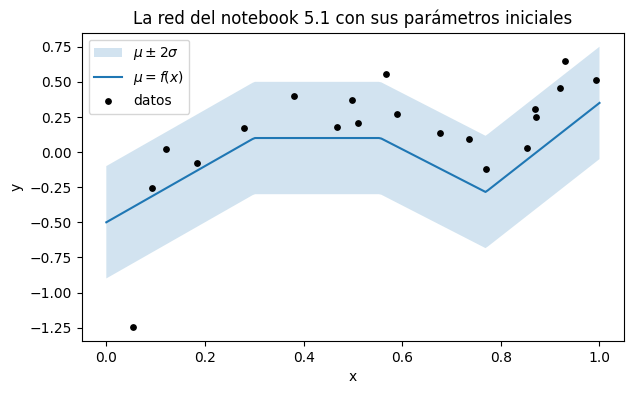

In [4]:
with torch.no_grad():
    mu_grilla = red(x_grilla).squeeze(1)
plt.figure(figsize=(7, 4))
plt.fill_between(x_grilla.squeeze(), mu_grilla - 2 * sigma, mu_grilla + 2 * sigma, alpha=0.2, label=r"$\mu \pm 2\sigma$")
plt.plot(x_grilla.squeeze(), mu_grilla, label=r"$\mu = f(x)$")
plt.scatter(x.squeeze(), y_regresion, color="black", s=15, zorder=3, label="datos")
plt.xlabel("x")
plt.ylabel("y")
plt.title("La red del notebook 5.1 con sus parámetros iniciales")
plt.legend()
plt.show()

Con los parámetros iniciales la curva pasa, en promedio, 0.17 por debajo de los puntos. Un punto queda muy fuera de la banda: el de $x = 0.05$, $y = -1.24$, a 0.85 de la curva. Solo ese punto aporta 0.72 de los 2.02 de la suma de cuadrados, porque el cuadrado agranda los residuos grandes.

## 4. Verosimilitud, log-verosimilitud y mínimos cuadrados

El notebook 5.1 mueve un solo parámetro, el sesgo de la salida $\beta_1$, entre 0 y 1, y calcula las tres cantidades para cada valor:

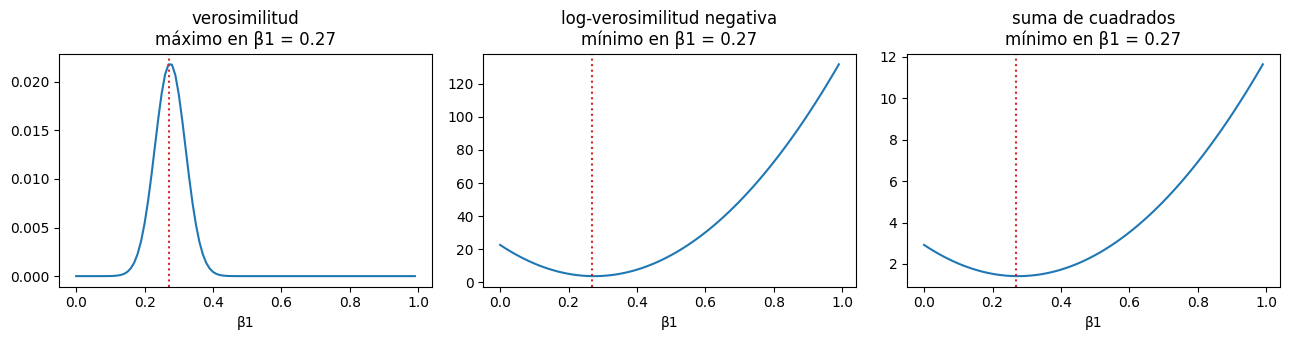

el β1 exacto: 0.1 + media de los residuos = 0.2747


In [5]:
valores_b1 = torch.arange(0, 1, 0.01)
curvas = {"verosimilitud": [], "log-verosimilitud negativa": [], "suma de cuadrados": []}
for b1 in valores_b1:
    with torch.no_grad():
        red[2].bias.fill_(b1)
        mu = red(x).squeeze(1)
    d = densidad_normal(y_regresion, mu, sigma)
    curvas["verosimilitud"].append(d.prod().item())
    curvas["log-verosimilitud negativa"].append(-d.log().sum().item())
    curvas["suma de cuadrados"].append(((y_regresion - mu) ** 2).sum().item())

fig, ejes = plt.subplots(1, 3, figsize=(13, 3.5))
for eje, (nombre, valores) in zip(ejes, curvas.items()):
    valores = torch.tensor(valores)
    mejor = valores.argmax() if nombre == "verosimilitud" else valores.argmin()
    eje.plot(valores_b1, valores)
    eje.axvline(valores_b1[mejor], color="tab:red", linestyle=":")
    eje.set_title(f"{nombre}\n{'máximo' if nombre == 'verosimilitud' else 'mínimo'} en β1 = {valores_b1[mejor]:.2f}")
    eje.set_xlabel("β1")
plt.tight_layout()
plt.show()

with torch.no_grad():
    red[2].bias.fill_(0.1)
    residuo = y_regresion - red(x).squeeze(1)
print(f"el β1 exacto: 0.1 + media de los residuos = {0.1 + residuo.mean():.4f}")

Las tres curvas tienen su extremo en el mismo lugar, $\beta_1 = 0.27$ en la grilla. El valor exacto es 0.2747: el sesgo de salida óptimo es el que deja los residuos con media 0. Las formas son muy distintas: la verosimilitud es un pico angosto, que vale 0.02 en su máximo y casi 0 en el resto, mientras la log-verosimilitud negativa y la suma de cuadrados son parábolas suaves, mucho más cómodas para un optimizador. Con $\sigma$ fija, la log-verosimilitud negativa es la suma de cuadrados multiplicada por $1/(2\sigma^2) = 12.5$, más una constante: son la misma función con otra escala.

El notebook 5.1 deja después $\beta_1 = 0.27$ y mueve $\sigma$, el otro parámetro de la distribución:

In [6]:
with torch.no_grad():
    red[2].bias.fill_(0.27)
    mu = red(x).squeeze(1)
valores_sigma = torch.arange(0.1, 0.5, 0.005)
nll_sigma = torch.stack([-densidad_normal(y_regresion, mu, s).log().sum() for s in valores_sigma])
cuadrados = ((y_regresion - mu) ** 2).sum()

print(f"suma de cuadrados con β1 = 0.27: {cuadrados:.4f}, para cualquier σ")
print(f"σ que minimiza la log-verosimilitud negativa en la grilla: {valores_sigma[nll_sigma.argmin()]:.3f}")
print(f"σ exacto, la raíz del error cuadrático medio:              {torch.sqrt(cuadrados / len(mu)):.4f}")

suma de cuadrados con β1 = 0.27: 1.4109, para cualquier σ
σ que minimiza la log-verosimilitud negativa en la grilla: 0.265
σ exacto, la raíz del error cuadrático medio:              0.2656


La suma de cuadrados no cambia con $\sigma$: los mínimos cuadrados no dicen nada sobre el tamaño del ruido. La log-verosimilitud sí: su mínimo está en $\sigma = 0.265$ en la grilla, y el valor exacto sale de derivar $N \log\sigma + \text{SSE}/(2\sigma^2)$ e igualar a cero: $\sigma^2 = \text{SSE}/N$, la varianza de los residuos. La sección 5.3.3 del libro (*Estimating variance*) hace este mismo razonamiento: con la máxima verosimilitud se estima la incertidumbre de las predicciones, no solo las predicciones.

## 5. Por qué el logaritmo

Con 20 puntos la verosimilitud ya es 0.0000106. Cada punto nuevo multiplica por otra densidad, y con más datos el producto se sale del rango de los números de punto flotante. Lo vemos repitiendo los mismos 20 puntos varias veces:

In [7]:
print(f"{'puntos':>7s} {'producto en float32':>20s} {'producto en float64':>20s} {'suma de logaritmos':>19s}")
for copias in [1, 5, 10, 50, 100]:
    d = densidades.repeat(copias)
    print(f"{len(d):7d} {d.float().prod().item():20.4g} {d.prod().item():20.4g} {d.log().sum().item():19.2f}")
for tipo in (torch.float32, torch.float64):
    menor = torch.nextafter(torch.tensor(0.0, dtype=tipo), torch.tensor(1.0, dtype=tipo))
    print(f"menor número positivo en {str(tipo)[6:]}: {menor.item():.3g}")

 puntos  producto en float32  producto en float64  suma de logaritmos
     20            1.062e-05            1.062e-05              -11.45
    100            1.353e-25            1.353e-25              -57.26
    200                    0            1.831e-50             -114.52
   1000                    0            2.06e-249             -572.62
   2000                    0                    0            -1145.24
menor número positivo en float32: 1.4e-45
menor número positivo en float64: 4.94e-324


Con 200 puntos, en `float32` el producto ya es exactamente 0: el valor verdadero, $1.8 \times 10^{-50}$, es menor que el número positivo más chico que se puede representar. En `float64` aguanta más, pero con 2000 puntos también es 0. Un conjunto de entrenamiento real tiene miles o millones de datos. La suma de logaritmos, en cambio, es solo $-11.45$ por cada copia, sin ningún problema. Además, un 0 no tiene gradiente útil: aunque la verosimilitud y su logaritmo tienen el mismo máximo, solo con el logaritmo se puede calcular.

## 6. Clasificación binaria: el notebook 5.2

Para una respuesta de sí o no, la distribución es una Bernoulli con parámetro $\lambda = Pr(y = 1)$, que tiene que estar entre 0 y 1. La red predice un número cualquiera y la sigmoide lo lleva a ese intervalo: $\lambda = \text{sig}(f(x, \boldsymbol\phi))$.

$$Pr(y \mid \lambda) = \lambda^{y} (1 - \lambda)^{1 - y}$$

Mismos $x$, otras etiquetas y otra capa de salida:

verosimilitud:              0.000070237   (Prince: 0.000070237)
log-veros. negativa:        9.563639387   (Prince: 9.563639387)
BCE con logits, sumada:     9.563639387

mínimo de la log-verosimilitud negativa: 8.0165 en β1 = 1.6


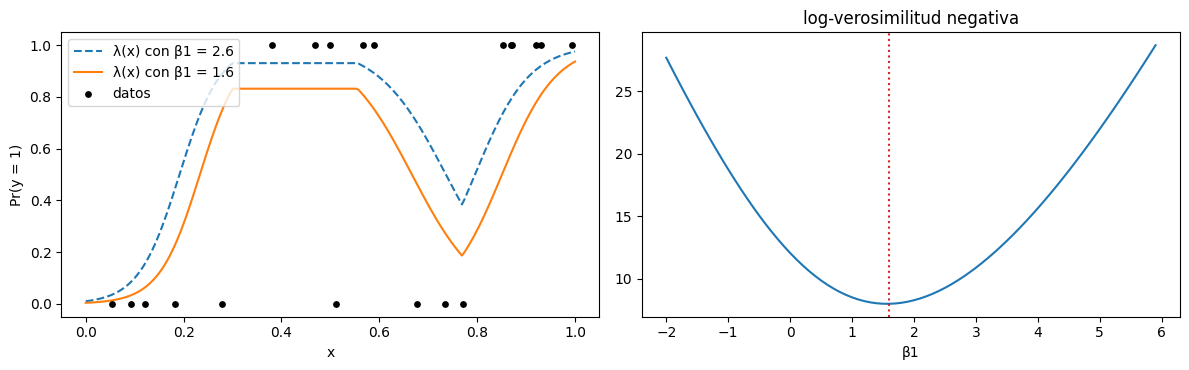

In [8]:
y_binaria = torch.tensor([0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1.0])

red = red_de_prince([[-24.0, -8.0, 50.0]], [2.6])
with torch.no_grad():
    logits = red(x).squeeze(1)
lam = torch.sigmoid(logits)
verosimilitud = (lam ** y_binaria * (1 - lam) ** (1 - y_binaria)).prod()
print(f"verosimilitud:              {verosimilitud:.9f}   (Prince: 0.000070237)")
print(f"log-veros. negativa:        {-verosimilitud.log():.9f}   (Prince: 9.563639387)")
print(f"BCE con logits, sumada:     {F.binary_cross_entropy_with_logits(logits, y_binaria, reduction='sum'):.9f}")

valores_b1 = torch.arange(-2, 6, 0.1)
nll_b1 = torch.stack([F.binary_cross_entropy_with_logits(logits - 2.6 + b1, y_binaria, reduction="sum")
                      for b1 in valores_b1])
mejor_b1 = valores_b1[nll_b1.argmin()].item()
print(f"\nmínimo de la log-verosimilitud negativa: {nll_b1.min():.4f} en β1 = {mejor_b1:.1f}")

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
for b1, estilo in [(2.6, "--"), (mejor_b1, "-")]:
    with torch.no_grad():
        red[2].bias.fill_(b1)
        ejes[0].plot(x_grilla.squeeze(), torch.sigmoid(red(x_grilla)).squeeze(), estilo, label=f"λ(x) con β1 = {b1:.1f}")
ejes[0].scatter(x.squeeze(), y_binaria, color="black", s=15, zorder=3, label="datos")
ejes[0].set_xlabel("x")
ejes[0].set_ylabel("Pr(y = 1)")
ejes[0].legend(loc="upper left")
ejes[1].plot(valores_b1, nll_b1)
ejes[1].axvline(mejor_b1, color="tab:red", linestyle=":")
ejes[1].set_xlabel("β1")
ejes[1].set_title("log-verosimilitud negativa")
plt.tight_layout()
plt.show()

Los dos valores coinciden con los de Prince, y `F.binary_cross_entropy_with_logits` sumada da la misma log-verosimilitud negativa. El mínimo está en $\beta_1 = 1.6$, un punto más abajo que el valor inicial. Como la sigmoide es creciente, bajar $\beta_1$ baja $\lambda$ en todo el eje. El modelo inicial daba 0.93 en la meseta entre 0.3 y 0.55, donde uno de los cuatro puntos es 0, y casi 0.7 cerca de $x = 0.7$, donde hay tres 0. Con $\beta_1 = 1.6$ queda en 0.83 en la meseta y más abajo cerca de 0.7. La forma de la curva no cambia, porque la fijan los otros pesos.

## 7. Varias clases: el notebook 5.3

Para una de $K$ clases, la distribución es una categórica con $K$ probabilidades $\lambda_1, \dots, \lambda_K$ que suman 1. La red tiene $K$ salidas y la función softmax las convierte en esas probabilidades. La capa de salida pasa a tener 3 sesgos y una matriz de 3×3 pesos:

verosimilitud:                0.000000041   (Prince: 0.000000041)
log-veros. negativa:          17.015457867  (Prince: 17.015457867)
entropía cruzada, sumada:     17.015457867

mínimo de la log-verosimilitud negativa: 14.1666 en β1[0] = 0.6


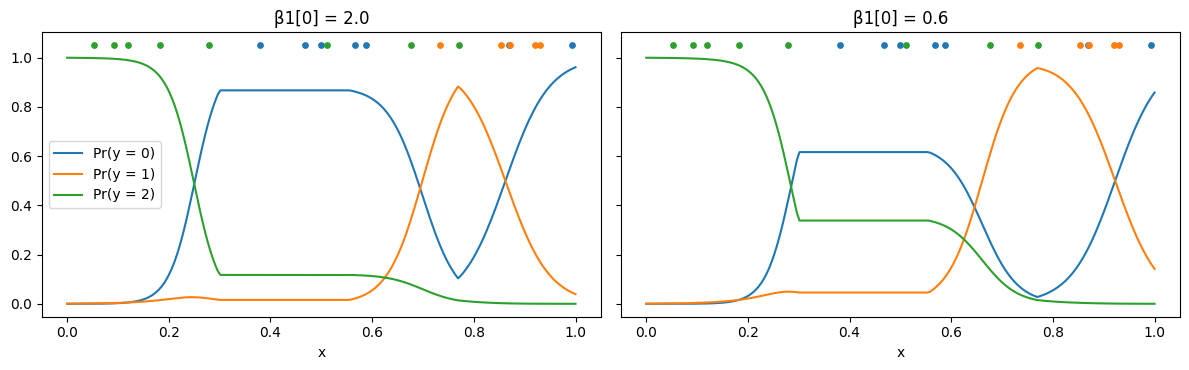

In [9]:
y_clase = torch.tensor([2, 0, 1, 2, 1, 0, 0, 2, 2, 0, 2, 0, 2, 0, 1, 2, 1, 2, 1, 0])

red = red_de_prince([[-24.0, -8.0, 50.0], [-2.0, 8.0, -30.0], [16.0, -8.0, -8.0]], [2.0, -2.0, 0.0])
with torch.no_grad():
    logits = red(x)
probabilidades = logits.softmax(dim=1)
verosimilitud = probabilidades[torch.arange(len(y_clase)), y_clase].prod()
print(f"verosimilitud:                {verosimilitud:.9f}   (Prince: 0.000000041)")
print(f"log-veros. negativa:          {-verosimilitud.log():.9f}  (Prince: 17.015457867)")
print(f"entropía cruzada, sumada:     {F.cross_entropy(logits, y_clase, reduction='sum'):.9f}")

nll_b1 = []
for b1 in valores_b1:
    movidos = logits.clone()
    movidos[:, 0] += b1 - 2.0          # cambiar β1[0] solo mueve el primer logit
    nll_b1.append(F.cross_entropy(movidos, y_clase, reduction="sum"))
nll_b1 = torch.stack(nll_b1)
mejor_b1 = valores_b1[nll_b1.argmin()].item()
print(f"\nmínimo de la log-verosimilitud negativa: {nll_b1.min():.4f} en β1[0] = {mejor_b1:.1f}")

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
colores = ["tab:blue", "tab:orange", "tab:green"]
for eje, b1 in zip(ejes, [2.0, mejor_b1]):
    with torch.no_grad():
        red[2].bias[0] = b1
        p = red(x_grilla).softmax(dim=1)
    for k in range(3):
        eje.plot(x_grilla.squeeze(), p[:, k], color=colores[k], label=f"Pr(y = {k})")
        eje.scatter(x[y_clase == k].squeeze(1), torch.full(((y_clase == k).sum().item(),), 1.05), color=colores[k], s=15)
    eje.set_title(f"β1[0] = {b1:.1f}")
    eje.set_xlabel("x")
ejes[0].legend(loc="center left")
plt.tight_layout()
plt.show()

Otra vez coinciden los dos valores, y `F.cross_entropy` con `reduction="sum"` es exactamente la log-verosimilitud negativa de la categórica. El mínimo está en $\beta_1[0] = 0.6$. Bajar el logit de la clase 0 le quita probabilidad para repartirla entre las otras dos: en la meseta, $Pr(y = 0)$ baja de 0.87 a 0.62 y $Pr(y = 2)$ sube de 0.12 a 0.34. Lo que se gana está en los puntos de clase 2 que el modelo inicial consideraba casi imposibles, como el de $x = 0.51$, dentro de la meseta.

En los tres notebooks el máximo de la verosimilitud y el mínimo de la log-verosimilitud negativa caen en el mismo parámetro, aunque en los dos últimos la pérdida ya no es una suma de cuadrados.

## 8. Una varianza que depende de la entrada

Hasta aquí $\sigma$ era fija. La sección 5.3.4 del libro muestra que la receta también sirve para que la red la prediga: basta con una segunda salida. Si el ruido de los datos cambia con $x$ (los estadísticos lo llaman **heterocedasticidad**), un modelo con varianza fija no lo puede representar.

Generamos datos con esa forma: $y = \sin(3x) + \varepsilon$, con un ruido cuya desviación crece de 0.05 a la izquierda hasta 0.45 a la derecha. La red tiene dos salidas: la media, y otra que la función `softplus` convierte en una varianza positiva. Como pérdida usamos la log-verosimilitud negativa de la gaussiana, escrita a mano y comprobada contra `nn.GaussianNLLLoss`.

In [10]:
def desviacion_real(x):
    return 0.05 + 0.2 * (x + 1)


def datos_ruido_variable(n, semilla):
    g = torch.Generator().manual_seed(semilla)
    x = torch.rand(n, 1, generator=g) * 2 - 1
    return x, torch.sin(3 * x) + desviacion_real(x) * torch.randn(n, 1, generator=g)


def red_pequena(salidas, activacion=nn.ReLU, ancho=64):
    torch.manual_seed(0)
    return nn.Sequential(nn.Linear(1, ancho), activacion(), nn.Linear(ancho, ancho), activacion(), nn.Linear(ancho, salidas))


def entrenar(modelo, perdida, pasos, lr):
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    for _ in range(pasos):
        valor = perdida(modelo)
        optimizador.zero_grad()
        valor.backward()
        optimizador.step()
    return valor.item()


def nll_gaussiana(mu, varianza, y):
    return (0.5 * torch.log(2 * math.pi * varianza) + (y - mu) ** 2 / (2 * varianza)).mean()


def media_y_varianza(salida):
    return salida[:, :1], F.softplus(salida[:, 1:]) + 1e-6


x_r, y_r = datos_ruido_variable(1000, semilla=0)
x_r_prueba, y_r_prueba = datos_ruido_variable(5000, semilla=1)

inicio = time.perf_counter()
fija = red_pequena(1)
entrenar(fija, lambda m: F.mse_loss(m(x_r), y_r), pasos=3000, lr=3e-3)
variable = red_pequena(2)
entrenar(variable, lambda m: nll_gaussiana(*media_y_varianza(m(x_r)), y_r), pasos=3000, lr=3e-3)
print(f"dos modelos entrenados en {time.perf_counter() - inicio:.0f} s")

with torch.no_grad():
    mu, varianza = media_y_varianza(variable(x_r))
    print(f"\nla pérdida a mano:     {nll_gaussiana(mu, varianza, y_r):.6f}")
    print(f"nn.GaussianNLLLoss:    {nn.GaussianNLLLoss(full=True)(mu, y_r, varianza):.6f}")

    # al modelo de varianza fija le damos la mejor σ posible: la raíz de su error cuadrático medio
    varianza_fija = F.mse_loss(fija(x_r), y_r)
    print(f"\nσ única del modelo de varianza fija: {varianza_fija.sqrt():.3f}")
    nll_fija = nll_gaussiana(fija(x_r_prueba), varianza_fija, y_r_prueba)
    nll_variable = nll_gaussiana(*media_y_varianza(variable(x_r_prueba)), y_r_prueba)
    print(f"log-verosimilitud negativa en datos nuevos: {nll_fija:.3f} con varianza fija, {nll_variable:.3f} con varianza variable")

    puntos = torch.tensor([[-0.9], [0.0], [0.9]])
    _, var_puntos = media_y_varianza(variable(puntos))
    for p, v in zip(puntos.squeeze(1), var_puntos.squeeze(1)):
        print(f"  x = {p:4.1f}: σ predicha {v.sqrt():.3f}, σ real {desviacion_real(p):.3f}")

dos modelos entrenados en 25 s

la pérdida a mano:     -0.132633
nn.GaussianNLLLoss:    -0.132633

σ única del modelo de varianza fija: 0.259
log-verosimilitud negativa en datos nuevos: 0.139 con varianza fija, -0.095 con varianza variable
  x = -0.9: σ predicha 0.072, σ real 0.070
  x =  0.0: σ predicha 0.242, σ real 0.250
  x =  0.9: σ predicha 0.374, σ real 0.430


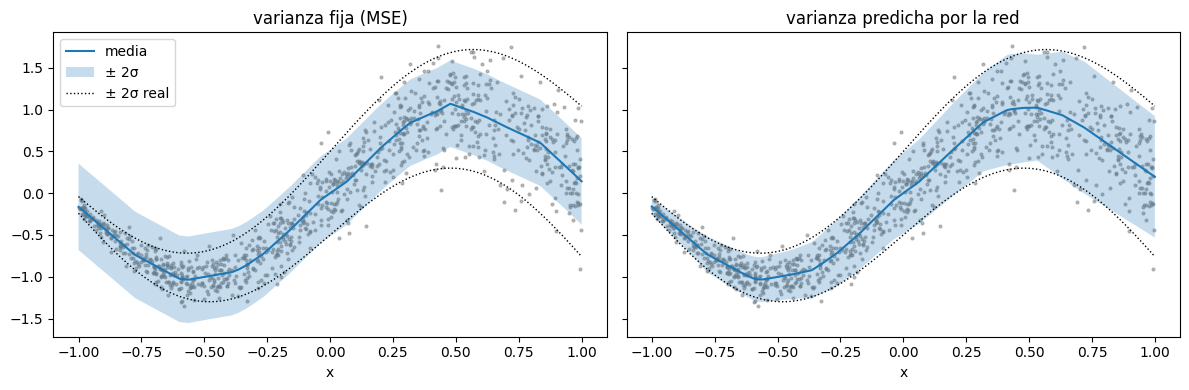

In [11]:
x_ordenado = torch.linspace(-1, 1, 300)[:, None]
with torch.no_grad():
    mu_fija = fija(x_ordenado).squeeze(1)
    mu_var, var_var = media_y_varianza(variable(x_ordenado))
    mu_var, sigma_var = mu_var.squeeze(1), var_var.sqrt().squeeze(1)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for eje, centro, ancho, titulo in [(ejes[0], mu_fija, varianza_fija.sqrt().expand(300), "varianza fija (MSE)"),
                                    (ejes[1], mu_var, sigma_var, "varianza predicha por la red")]:
    eje.scatter(x_r.squeeze(), y_r.squeeze(), s=4, color="gray", alpha=0.5)
    eje.plot(x_ordenado.squeeze(), centro, color="tab:blue", label="media")
    eje.fill_between(x_ordenado.squeeze(), centro - 2 * ancho, centro + 2 * ancho, alpha=0.25, label="± 2σ")
    eje.plot(x_ordenado.squeeze(), torch.sin(3 * x_ordenado).squeeze() + 2 * desviacion_real(x_ordenado).squeeze(),
             "k:", linewidth=1, label="± 2σ real")
    eje.plot(x_ordenado.squeeze(), torch.sin(3 * x_ordenado).squeeze() - 2 * desviacion_real(x_ordenado).squeeze(), "k:", linewidth=1)
    eje.set_title(titulo)
    eje.set_xlabel("x")
ejes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

Las dos medias son casi iguales: ambos modelos aprenden $\sin(3x)$. La diferencia está en la incertidumbre. El modelo de varianza fija usa la misma $\sigma = 0.259$ en todo el eje, así que su banda es demasiado ancha a la izquierda (±0.52 donde el ruido real es ±0.14) y demasiado angosta a la derecha. El modelo con varianza predicha sigue la forma real: estima 0.072 en $x = -0.9$, donde la real es 0.070, y 0.242 en $x = 0$, donde es 0.250. En $x = 0.9$ se queda corto (0.374 contra 0.430): es el borde de los datos, con menos puntos a un lado.

En datos nuevos, la log-verosimilitud negativa baja de 0.139 a $-0.095$. Que sea negativa no es un error: una densidad continua puede valer más de 1, y su logaritmo ser positivo.

La comprobación contra `nn.GaussianNLLLoss` da el mismo valor. Esta pérdida tiene una trampa conocida: la red puede bajarla achicando la varianza donde ya acierta, en vez de mejorar la media donde falla, y a veces la media se aprende peor que con MSE (Seitzer y otros, 2022). Aquí no pasó: las dos medias son casi iguales.

## 9. Conteos: la distribución de Poisson

El problema 5.6 del libro pide construir la pérdida para predecir **conteos**: cuántos peatones pasarán por una esquina en el próximo minuto. La respuesta es un entero no negativo, y la distribución natural es la de Poisson, con un parámetro $\lambda > 0$ que es a la vez su media y su varianza:

$$Pr(y = k \mid \lambda) = \frac{\lambda^k e^{-\lambda}}{k!} \qquad -\log Pr(y \mid \lambda) = \lambda - y \log \lambda + \log(y!)$$

La red predice $\log \lambda$, y el exponencial garantiza que $\lambda$ sea positiva. PyTorch trae `nn.PoissonNLLLoss`, que con `log_input=True` espera justamente $\log \lambda$. Por defecto omite el término $\log(y!)$, que no depende de la red y no mueve el mínimo.

In [12]:
def tasa_real(x):
    return torch.exp(1.0 + 1.5 * torch.sin(2 * x))


g = torch.Generator().manual_seed(2)
x_c = torch.rand(1000, 1, generator=g) * 2 - 1
y_c = torch.poisson(tasa_real(x_c), generator=g)
print(f"conteos entre {y_c.min():.0f} y {y_c.max():.0f}, media {y_c.mean():.2f}; ceros: {(y_c == 0).sum().item()} de {len(y_c)}")


def nll_poisson(log_tasa, y):
    return (torch.exp(log_tasa) - y * log_tasa + torch.lgamma(y + 1)).mean()


poisson = red_pequena(1)
entrenar(poisson, lambda m: nll_poisson(m(x_c), y_c), pasos=3000, lr=3e-3)
cuadratico = red_pequena(1)
entrenar(cuadratico, lambda m: F.mse_loss(m(x_c), y_c), pasos=3000, lr=3e-3)

with torch.no_grad():
    log_tasa = poisson(x_c)
    print(f"\nla pérdida a mano:                          {nll_poisson(log_tasa, y_c):.6f}")
    print(f"nn.PoissonNLLLoss:                          {nn.PoissonNLLLoss(log_input=True)(log_tasa, y_c):.6f}")
    print(f"nn.PoissonNLLLoss + media de log(y!):       {nn.PoissonNLLLoss(log_input=True)(log_tasa, y_c) + torch.lgamma(y_c + 1).mean():.6f}")
    print(f"nn.PoissonNLLLoss(full=True):               {nn.PoissonNLLLoss(log_input=True, full=True)(log_tasa, y_c):.6f}")

conteos entre 0 y 20, media 4.59; ceros: 211 de 1000



la pérdida a mano:                          1.813010
nn.PoissonNLLLoss:                          -4.398119
nn.PoissonNLLLoss + media de log(y!):       1.813010
nn.PoissonNLLLoss(full=True):               1.802145


La pérdida escrita a mano coincide con `nn.PoissonNLLLoss` más la media de $\log(y!)$: PyTorch omite ese término, y por eso su valor sale negativo, $-4.40$, aunque una log-verosimilitud negativa de un conteo nunca lo es. Lo curioso es `full=True`: da 1.8021, no 1.8130. La documentación de PyTorch explica que no suma $\log(y!)$, sino la **aproximación de Stirling** $y \log y - y + \frac{1}{2}\log(2\pi y)$, y solo para $y > 1$. Para el entrenamiento da igual, porque el término no depende de la red, pero el valor reportado no es exactamente la log-verosimilitud negativa.

    tramo de x    n  media  varianza  λ predicha  ceros   e^-λ
  -1.0 a -0.6  223   0.68      0.75        0.68  52.0%  51.3%
  -0.6 a -0.2  185   0.91      0.98        0.95  41.6%  39.4%
  -0.2 a  0.2  197   2.78      3.60        2.82   9.1%   8.9%
   0.2 a  0.6  211   7.58      9.53        7.68   0.0%   0.1%
   0.6 a  1.0  184  11.52     11.03       11.58   0.0%   0.0%

predicciones negativas del modelo con MSE: 0; menor predicción: 0.62


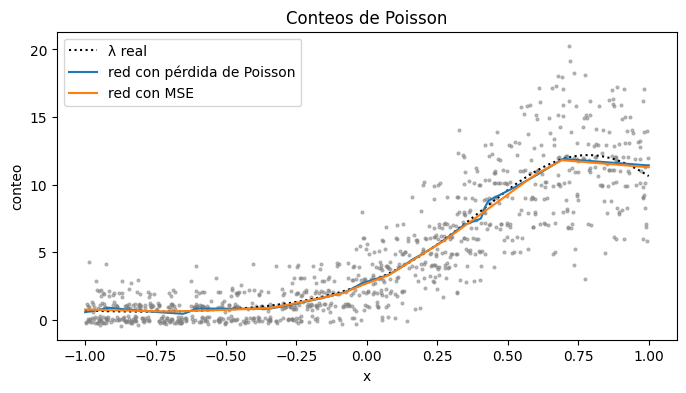

In [13]:
with torch.no_grad():
    tasa_poisson = torch.exp(poisson(x_c)).squeeze(1)
    tasa_cuadratico = cuadratico(x_c).squeeze(1)
print(f"{'tramo de x':>14s} {'n':>4s} {'media':>6s} {'varianza':>9s} {'λ predicha':>11s} {'ceros':>6s} {'e^-λ':>6s}")
bordes = torch.linspace(-1, 1, 6)
for a, b in zip(bordes[:-1], bordes[1:]):
    en = ((x_c >= a) & (x_c < b)).squeeze(1)
    conteos = y_c.squeeze(1)[en]
    tasa = tasa_poisson[en].mean()
    print(f"{a:6.1f} a {b:4.1f} {en.sum().item():4d} {conteos.mean():6.2f} {conteos.var():9.2f} {tasa:11.2f} "
          f"{(conteos == 0).float().mean():6.1%} {torch.exp(-tasa_poisson[en]).mean():6.1%}")
print(f"\npredicciones negativas del modelo con MSE: {(tasa_cuadratico < 0).sum().item()}; "
      f"menor predicción: {tasa_cuadratico.min():.2f}")

x_ordenado = torch.linspace(-1, 1, 300)[:, None]
with torch.no_grad():
    plt.figure(figsize=(8, 4))
    plt.scatter(x_c.squeeze(), y_c.squeeze() + 0.15 * torch.randn(len(y_c), generator=g), s=4, color="gray", alpha=0.5)
    plt.plot(x_ordenado.squeeze(), tasa_real(x_ordenado).squeeze(), "k:", label="λ real")
    plt.plot(x_ordenado.squeeze(), torch.exp(poisson(x_ordenado)).squeeze(), label="red con pérdida de Poisson")
    plt.plot(x_ordenado.squeeze(), cuadratico(x_ordenado).squeeze(), label="red con MSE")
plt.xlabel("x")
plt.ylabel("conteo")
plt.legend()
plt.title("Conteos de Poisson")
plt.show()

En cada tramo, la media de los conteos coincide con la $\lambda$ predicha (0.68 y 0.68, 2.78 y 2.82, 11.52 y 11.58), y la fracción de ceros con $e^{-\lambda}$, la probabilidad de 0 bajo Poisson (52.0% y 51.3%, 9.1% y 8.9%). Esa segunda columna es algo que el modelo con MSE no puede dar: predice un número, no una distribución. En los tramos del medio la varianza observada supera la media (3.60 contra 2.78) porque $\lambda$ cambia dentro del tramo, de 1.5 a 4.9 entre $x = -0.2$ y $x = 0.2$, y la varianza total suma la de cada conteo y la de $\lambda$.

Las dos redes estiman la media casi igual: el MSE siempre estima la media, cualquiera sea la distribución. La pérdida de Poisson agrega lo demás: $\lambda > 0$ por construcción (aquí el modelo con MSE no predijo negativos, su mínimo fue 0.62, pero nada lo impedía) y una distribución completa, con la probabilidad de cada conteo.

## 10. Varias respuestas posibles: una mezcla de gaussianas

El problema 5.4 trata el caso en que, para una misma entrada, hay **varias respuestas** igual de válidas. Una gaussiana tiene un solo pico y no lo puede representar. La salida es una **mezcla** de $K$ gaussianas: la red predice, para cada componente, un peso $\pi_k$ (con softmax, para que sumen 1), una media $\mu_k$ y una desviación $\sigma_k$ (con exponencial, para que sea positiva). Es una **red de densidad de mezcla** (*mixture density network*), que el libro atribuye a Jacobs y otros (1991) y a Christopher Bishop (1994).

$$Pr(y \mid x) = \sum_{k=1}^{K} \pi_k(x)\, \mathcal{N}\big(y;\ \mu_k(x), \sigma_k(x)^2\big)$$

Usamos el ejemplo del artículo de Bishop. Se elige $y$ al azar entre 0 y 1 y se calcula $x = y + 0.3 \sin(2\pi y)$ más un poco de ruido. Predecir $x$ desde $y$ es fácil. Predecir $y$ desde $x$, el **problema inverso**, no lo es: para $x$ cerca de 0.5 hay tres valores de $y$ que lo producen.

El logaritmo de una suma de exponenciales se calcula con `torch.logsumexp`, por la misma razón numérica que en `01_depurar_un_modelo`.

In [14]:
def datos_inversos(n, semilla):
    g = torch.Generator().manual_seed(semilla)
    y = torch.rand(n, 1, generator=g)
    return y + 0.3 * torch.sin(2 * math.pi * y) + (torch.rand(n, 1, generator=g) - 0.5) * 0.2, y


K = 3


def mezcla(salida):
    logits_pi, mu, log_sigma = salida.split(K, dim=1)
    return F.log_softmax(logits_pi, dim=1), mu, log_sigma.exp()


def nll_mezcla(salida, y):
    log_pi, mu, sigma = mezcla(salida)
    log_normal = -0.5 * ((y - mu) / sigma) ** 2 - sigma.log() - 0.5 * math.log(2 * math.pi)
    return -torch.logsumexp(log_pi + log_normal, dim=1).mean()


x_i, y_i = datos_inversos(1000, semilla=0)
x_i_prueba, y_i_prueba = datos_inversos(20_000, semilla=1)

inicio = time.perf_counter()
una = red_pequena(1, activacion=nn.Tanh, ancho=32)
entrenar(una, lambda m: F.mse_loss(m(x_i), y_i), pasos=3000, lr=5e-3)
red_mezcla = red_pequena(3 * K, activacion=nn.Tanh, ancho=32)
entrenar(red_mezcla, lambda m: nll_mezcla(m(x_i), y_i), pasos=6000, lr=5e-3)
print(f"dos modelos entrenados en {time.perf_counter() - inicio:.0f} s")

with torch.no_grad():
    log_pi, mu, sigma = mezcla(red_mezcla(x_i_prueba))
    distribucion = torch.distributions.MixtureSameFamily(torch.distributions.Categorical(logits=log_pi),
                                                         torch.distributions.Normal(mu, sigma))
    print(f"\nla pérdida a mano en datos nuevos:        {nll_mezcla(red_mezcla(x_i_prueba), y_i_prueba):.4f}")
    print(f"con torch.distributions:                  {-distribucion.log_prob(y_i_prueba.squeeze(1)).mean():.4f}")
    sigma_una = F.mse_loss(una(x_i), y_i).sqrt()
    print(f"una sola gaussiana (la red con MSE y su mejor σ = {sigma_una:.3f}): "
          f"{nll_gaussiana(una(x_i_prueba), sigma_una ** 2, y_i_prueba):.4f}")

dos modelos entrenados en 25 s

la pérdida a mano en datos nuevos:        -1.1060
con torch.distributions:                  -1.1060
una sola gaussiana (la red con MSE y su mejor σ = 0.196): -0.2050


En datos nuevos, la mezcla obtiene una log-verosimilitud negativa de $-1.106$, contra $-0.205$ de una sola gaussiana. La diferencia de 0.9 por ejemplo significa que la mezcla le asigna a la respuesta correcta, en promedio geométrico, $e^{0.9} \approx 2.5$ veces más densidad. `torch.distributions.MixtureSameFamily` calcula lo mismo sin escribir la fórmula, y sirve para comprobarla.

¿Encontró la red las tres soluciones? Para $x = 0.5$ las podemos calcular: son los $y$ que cumplen $y + 0.3\sin(2\pi y) = 0.5$. Cuánto peso merece cada una también se puede calcular. Los $y$ se reparten parejo entre 0 y 1, y una rama donde $x$ cambia lentamente con $y$ junta más valores de $y$ cerca de cada $x$. Sin contar el ruido, el peso de cada solución es proporcional a $1 / |dx/dy|$, con $dx/dy = 1 + 0.6\pi\cos(2\pi y)$.

In [15]:
y_fino = torch.linspace(0, 1, 1_000_001)
x_fino = y_fino + 0.3 * torch.sin(2 * math.pi * y_fino)
cruces = torch.nonzero(torch.diff((x_fino > 0.5).int()) != 0).squeeze(1)    # donde x cruza 0.5
soluciones = y_fino[cruces]
pendiente = (1 + 0.6 * math.pi * torch.cos(2 * math.pi * soluciones)).abs()
peso_teorico = (1 / pendiente) / (1 / pendiente).sum()
print("soluciones exactas de x = 0.5:     ", [round(s, 3) for s in soluciones.tolist()])
print("peso esperado de cada una:         ", [round(p, 2) for p in peso_teorico.tolist()])

with torch.no_grad():
    log_pi, mu, sigma = mezcla(red_mezcla(torch.tensor([[0.5]])))
orden = mu[0].argsort()
print("medias de las componentes de la red:", [round(v, 3) for v in mu[0, orden].tolist()])
print("pesos de las componentes:          ", [round(v, 2) for v in log_pi[0, orden].exp().tolist()])
print("desviaciones de las componentes:   ", [round(v, 3) for v in sigma[0, orden].tolist()])
with torch.no_grad():
    print(f"predicción de la red con MSE:       {una(torch.tensor([[0.5]])).item():.3f}")

soluciones exactas de x = 0.5:      [0.21, 0.5, 0.79]
peso esperado de cada una:          [0.27, 0.45, 0.27]
medias de las componentes de la red: [0.213, 0.507, 0.771]
pesos de las componentes:           [0.27, 0.51, 0.22]
desviaciones de las componentes:    [0.041, 0.099, 0.043]
predicción de la red con MSE:       0.480


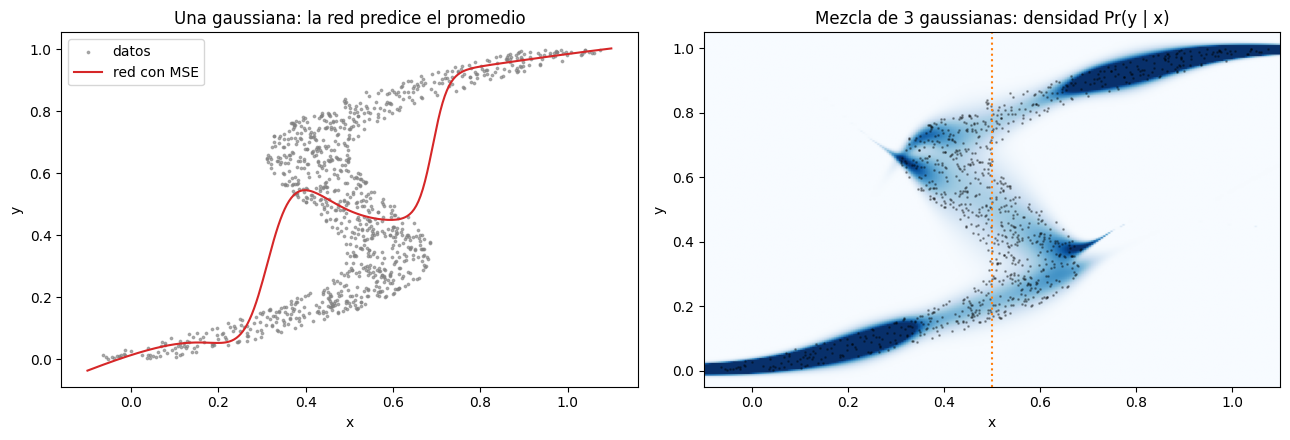

In [16]:
x_eje = torch.linspace(-0.1, 1.1, 240)
y_eje = torch.linspace(-0.05, 1.05, 220)
with torch.no_grad():
    log_pi, mu, sigma = mezcla(red_mezcla(x_eje[:, None]))
    log_normal = -0.5 * ((y_eje[None, :, None] - mu[:, None, :]) / sigma[:, None, :]) ** 2 - sigma[:, None, :].log() - 0.5 * math.log(2 * math.pi)
    densidad = torch.logsumexp(log_pi[:, None, :] + log_normal, dim=2).exp()          # (x, y)
    prediccion_una = una(x_eje[:, None]).squeeze(1)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
ejes[0].scatter(x_i.squeeze(), y_i.squeeze(), s=3, color="gray", alpha=0.6, label="datos")
ejes[0].plot(x_eje, prediccion_una, color="tab:red", label="red con MSE")
ejes[0].set_title("Una gaussiana: la red predice el promedio")
ejes[1].imshow(densidad.T.clamp(max=6), origin="lower", aspect="auto", cmap="Blues",
               extent=[x_eje[0].item(), x_eje[-1].item(), y_eje[0].item(), y_eje[-1].item()])
ejes[1].scatter(x_i.squeeze(), y_i.squeeze(), s=1, color="black", alpha=0.3)
ejes[1].axvline(0.5, color="tab:orange", linestyle=":")
ejes[1].set_title("Mezcla de 3 gaussianas: densidad Pr(y | x)")
for eje in ejes:
    eje.set_xlabel("x")
    eje.set_ylabel("y")
ejes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

La red encontró las tres soluciones de $x = 0.5$: sus componentes están en 0.213, 0.507 y 0.771, contra 0.21, 0.50 y 0.79 exactas. Los pesos también se acercan a los esperados: 0.27, 0.51 y 0.22, contra 0.27, 0.45 y 0.27. La componente del medio es además más ancha (0.099 contra unos 0.04), por la misma razón que pesa más: en esa rama $x$ cambia lento con $y$, así que el ruido en $x$ se traduce en más dispersión en $y$. La red con MSE predice 0.480, el promedio de las tres.

En el gráfico se ve el problema completo. La red con MSE pasa por el promedio de las ramas, y entre $x = 0.35$ y $0.45$, y entre $0.55$ y $0.65$, su curva cruza zonas donde no hay ningún dato. La mezcla dibuja las tres ramas como bandas separadas. Donde las ramas se doblan, cerca de $x = 0.3$ y $x = 0.67$, la densidad muestra unas puntas raras: ahí una componente se apaga mientras otra la reemplaza, y con pocos datos la transición queda mal definida.

## 11. Entropía cruzada y divergencia de Kullback-Leibler

La sección 5.7 del libro llega a la misma pérdida por otro camino. Describe los datos como una distribución empírica $q$, que pone una masa puntual en cada dato observado, y busca el modelo cuya distribución $p$ esté más cerca de $q$. Para medir esa cercanía usa la **divergencia de Kullback-Leibler**. Para distribuciones sobre $K$ clases es:

$$D_{KL}(q \,\|\, p) = \sum_k q_k \log \frac{q_k}{p_k} = \underbrace{-\sum_k q_k \log p_k}_{\text{entropía cruzada } H(q,\,p)} - \underbrace{\left(-\sum_k q_k \log q_k\right)}_{\text{entropía } H(q)}$$

Es decir, $H(q, p) = H(q) + D_{KL}(q \,\|\, p)$. $H(q)$ no depende del modelo, y minimizar la entropía cruzada es minimizar la divergencia. Cuando $q$ pone toda la probabilidad en la etiqueta correcta (un vector *one-hot*), $H(q) = 0$ y la entropía cruzada es exactamente la log-verosimilitud negativa de las secciones anteriores.

`F.cross_entropy` acepta como objetivo, además de índices de clase, distribuciones completas. Comprobamos la identidad con objetivos al azar:

In [17]:
g = torch.Generator().manual_seed(3)
logits = torch.randn(5, 4, generator=g)
q = torch.rand(5, 4, generator=g).softmax(dim=1)          # 5 distribuciones objetivo sobre 4 clases

entropia_cruzada = F.cross_entropy(logits, q)
entropia = -(q * q.log()).sum(dim=1).mean()
kl = F.kl_div(logits.log_softmax(dim=1), q, reduction="batchmean")
print(f"H(q, p)              = {entropia_cruzada:.6f}")
print(f"H(q) + KL(q || p)    = {entropia + kl:.6f}   (H(q) = {entropia:.6f}, KL = {kl:.6f})")

H(q, p)              = 1.534292
H(q) + KL(q || p)    = 1.534292   (H(q) = 1.369788, KL = 0.164504)


El mínimo de $H(q, p)$, entonces, está en $p = q$, y vale $H(q)$. Con etiquetas *one-hot*, $p = q$ exige que la clase correcta tenga probabilidad 1, algo que softmax solo alcanza con logits infinitos: la red tiene un incentivo para agrandar sus logits sin límite. Es una de las fuentes de la sobreconfianza que corrigió el escalado de temperatura en `02_evaluar_mas_alla_de_la_exactitud`.

El **suavizado de etiquetas** (*label smoothing*, Szegedy y otros, 2016) cambia el objetivo: la clase correcta recibe $1 - \varepsilon + \varepsilon/K$, y cada una de las otras $\varepsilon / K$. El argumento `label_smoothing` de `F.cross_entropy` es exactamente eso:

In [18]:
etiquetas = torch.tensor([0, 3, 1, 1, 2])
epsilon, clases = 0.1, 4
suave = (1 - epsilon) * F.one_hot(etiquetas, clases) + epsilon / clases
print(f"label_smoothing=0.1:             {F.cross_entropy(logits, etiquetas, label_smoothing=epsilon):.6f}")
print(f"objetivo suavizado a mano:       {F.cross_entropy(logits, suave):.6f}")

label_smoothing=0.1:             1.469834
objetivo suavizado a mano:       1.469834


Con el objetivo suavizado, el mínimo $p = q$ ya no exige logits infinitos. Para $K = 10$ y $\varepsilon = 0.1$, la clase correcta debe tener $0.91$ y cada otra $0.01$, así que la diferencia entre el logit correcto y los demás debe ser $\log(0.91 / 0.01) = \log 91 \approx 4.51$. Lo vemos optimizando directamente los 10 logits de un solo ejemplo:

In [19]:
def optimizar_logits(suavizado, pasos):
    logits = torch.zeros(1, 10, requires_grad=True)
    optimizador = torch.optim.SGD([logits], lr=1.0)
    historia = {}
    for paso in range(1, pasos + 1):
        perdida = F.cross_entropy(logits, torch.tensor([0]), label_smoothing=suavizado)
        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()
        if paso in (10, 100, 1000, 10_000):
            historia[paso] = (logits[0, 0] - logits[0, 1]).item(), perdida.item()
    return historia


print(f"{'pasos':>6s} {'sin suavizar: diferencia, pérdida':>36s} {'suavizado 0.1: diferencia, pérdida':>38s}")
duro, suavizado = optimizar_logits(0.0, 10_000), optimizar_logits(0.1, 10_000)
for paso in duro:
    print(f"{paso:6d} {duro[paso][0]:20.2f} {duro[paso][1]:14.6f} {suavizado[paso][0]:21.2f} {suavizado[paso][1]:15.6f}")
q = torch.full((10,), 0.01)
q[0] = 0.91
print(f"\nlog 91 = {math.log(91):.2f};  H(q) del objetivo suavizado = {-(q * q.log()).sum():.6f}")

 pasos    sin suavizar: diferencia, pérdida     suavizado 0.1: diferencia, pérdida


    10                 4.29       0.131779                  3.81        0.532599
   100                 6.87       0.009403                  4.51        0.500288
  1000                 9.21       0.000905                  4.51        0.500288
 10000                11.51       0.000090                  4.51        0.500288

log 91 = 4.51;  H(q) del objetivo suavizado = 0.500288


Sin suavizar, la diferencia entre el logit correcto y los demás no deja de crecer: 4.29 tras 10 pasos, 6.87 tras 100, 9.21 tras 1000 y 11.51 tras 10.000, unos 2.3 más por cada factor de 10 en los pasos. La pérdida tiende a 0 sin llegar nunca. Con suavizado 0.1, a los 100 pasos la diferencia se detiene en 4.51 = $\log 91$, y la pérdida en 0.500288, exactamente $H(q)$: el mínimo que permite la teoría, donde la divergencia es 0. El suavizado le pone un techo a la confianza: aquí, 0.91 para la clase correcta.

## 12. Resumen

- La receta del capítulo 5: elegir una distribución para la respuesta, hacer que la red prediga sus parámetros (con funciones que respeten sus restricciones) y minimizar la log-verosimilitud negativa. Los tres notebooks de Prince quedan reproducidos en PyTorch con sus 9 decimales.
- Maximizar la verosimilitud, minimizar su logaritmo negativo y, para una gaussiana con $\sigma$ fija, minimizar la suma de cuadrados dan **el mismo** parámetro. Pero solo la verosimilitud estima $\sigma$: su mejor valor es la raíz del error cuadrático medio.
- El producto de densidades se sale del rango de los números de punto flotante con unos cientos de datos. La suma de logaritmos no.
- Bernoulli con sigmoide da la entropía cruzada binaria, y categórica con softmax da la entropía cruzada: en PyTorch, `BCEWithLogitsLoss` y `CrossEntropyLoss`.
- La misma receta da pérdidas nuevas. Una segunda salida para la varianza (`GaussianNLLLoss`) aprende un ruido que cambia con la entrada. Poisson (`PoissonNLLLoss`) da conteos con $\lambda > 0$ y una distribución completa, con la probabilidad de cada conteo. Una mezcla de gaussianas representa varias respuestas posibles, donde una sola gaussiana predice un promedio que puede no ser ninguna de ellas.
- `PoissonNLLLoss(full=True)` no suma $\log(y!)$ exacto, sino la aproximación de Stirling: la pérdida resultante no es exactamente la log-verosimilitud negativa.
- La entropía cruzada es la entropía del objetivo más la divergencia de Kullback-Leibler. Con etiquetas *one-hot* empuja los logits sin límite; con suavizado de etiquetas, su mínimo es finito.

## Ejercicios

1. En el notebook 5.1, ajusta $\beta_1$ y $\sigma$ a la vez con un optimizador en lugar de con grillas: convierte los dos en parámetros con `requires_grad=True`, minimiza la log-verosimilitud negativa, y comprueba que llegas a $\beta_1 \approx 0.2747$ y $\sigma \approx 0.2656$. (Pista: optimiza $\log \sigma$ en vez de $\sigma$.)
2. La sección 5.6 del libro trata respuestas con varias salidas independientes: la pérdida es la suma de las pérdidas de cada una. Genera datos con dos respuestas, una real y una binaria, y entrena una red con dos salidas y la suma de `GaussianNLLLoss` y `BCEWithLogitsLoss`.
3. Reemplaza la gaussiana de la sección 8 por una distribución de Laplace con escala predicha por la red. ¿Qué pérdida queda cuando la escala es fija? (Compara con `04-matematica-de-pytorch/03_funciones_de_perdida` del módulo 1.)
4. Entrena la red de mezcla de la sección 10 con $K = 1$ y con $K = 5$, y compara la log-verosimilitud negativa en los datos nuevos. ¿Qué hacen las componentes que sobran con $K = 5$?
5. Para predecir una dirección, como el rumbo del viento en el problema 5.3 del libro, Prince sugiere la distribución de von Mises, $Pr(y \mid \mu, \kappa) = \exp(\kappa\cos(y - \mu)) / (2\pi I_0(\kappa))$. Escribe su log-verosimilitud negativa (con `torch.special.i0e` para $I_0$) y úsala para ajustar una red que prediga ángulos.